In [1]:

import pandas as pd
import numpy as np
import zipfile
from pathlib import Path

# ZIP file is in the project root
zip_path = Path("phiusiil+phishing+url+dataset.zip")

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files inside ZIP:", z.namelist())

    csv_name = next(
        name for name in z.namelist()
        if name.lower().endswith(".csv")
    )

    with z.open(csv_name) as f:
        df = pd.read_csv(f)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()


Files inside ZIP: ['PhiUSIIL_Phishing_URL_Dataset.csv']
Dataset loaded successfully!
Shape: (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


In [2]:
# 1 = Phishing, 0 = Legitimate
df["target"] = (df["label"] == 0).astype(int)

In [3]:

# Original dataset:
# label = 0 -> Phishing
# label = 1 -> Legitimate

# Convert to:
# target = 1 -> Phishing
# target = 0 -> Legitimate

df["target"] = (df["label"] == 0).astype(int)

print(df[["label", "target"]].head())

print("\nTarget distribution:")
print(df["target"].value_counts())


   label  target
0      1       0
1      1       0
2      1       0
3      1       0
4      1       0

Target distribution:
target
0    134850
1    100945
Name: count, dtype: int64


In [4]:

# Target variable
y = df["target"].copy()

# Keep domains separately for splitting later
groups = df["Domain"].copy()

# Exclude labels and identifiers from model inputs
X = df.drop(columns=[
    "label",
    "target",
    "FILENAME",
    "URL",
    "Domain",
    "TLD",
    "Title"
])

print("Feature matrix:", X.shape)
print("Target:", y.shape)
print("Domain groups:", groups.shape)

print("\nRemaining features:")
print(X.columns.tolist())


Feature matrix: (235795, 50)
Target: (235795,)
Domain groups: (235795,)

Remaining features:
['URLLength', 'DomainLength', 'IsDomainIP', 'URLSimilarityIndex', 'CharContinuationRate', 'TLDLegitimateProb', 'URLCharProb', 'TLDLength', 'NoOfSubDomain', 'HasObfuscation', 'NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfLettersInURL', 'LetterRatioInURL', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfOtherSpecialCharsInURL', 'SpacialCharRatioInURL', 'IsHTTPS', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [5]:
print("Missing values:", X.isnull().sum().sum())
print("Number of features:", X.shape[1])
print("Target classes:", y.unique())

Missing values: 0
Number of features: 50
Target classes: [0 1]


In [6]:

url_features = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS"
]


In [7]:

webpage_features = [
    "LineOfCode",
    "LargestLineLength",
    "HasTitle",
    "DomainTitleMatchScore",
    "URLTitleMatchScore",
    "HasFavicon",
    "Robots",
    "IsResponsive",
    "NoOfURLRedirect",
    "NoOfSelfRedirect",
    "HasDescription",
    "NoOfPopup",
    "NoOfiFrame",
    "HasExternalFormSubmit",
    "HasSocialNet",
    "HasSubmitButton",
    "HasHiddenFields",
    "HasPasswordField",
    "Bank",
    "Pay",
    "Crypto",
    "HasCopyrightInfo",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]


In [8]:

hybrid_features = url_features + webpage_features

print("URL features:", len(url_features))
print("Webpage features:", len(webpage_features))
print("Hybrid features:", len(hybrid_features))


URL features: 18
Webpage features: 28
Hybrid features: 46


In [9]:

# Check for missing feature names
missing_url = set(url_features) - set(X.columns)
missing_webpage = set(webpage_features) - set(X.columns)

print("Missing URL features:", missing_url)
print("Missing webpage features:", missing_webpage)

# Check whether there are overlapping columns
overlap = set(url_features) & set(webpage_features)
print("Overlapping features:", overlap)

# Verify total feature count
print("Total selected features:", len(hybrid_features))


Missing URL features: set()
Missing webpage features: set()
Overlapping features: set()
Total selected features: 46


In [10]:

X_url = X[url_features].copy()

X_webpage = X[webpage_features].copy()

X_hybrid = X[hybrid_features].copy()

print("URL dataset:", X_url.shape)
print("Webpage dataset:", X_webpage.shape)
print("Hybrid dataset:", X_hybrid.shape)


URL dataset: (235795, 18)
Webpage dataset: (235795, 28)
Hybrid dataset: (235795, 46)


In [11]:

import numpy as np

for name, data in {
    "URL": X_url,
    "Webpage": X_webpage,
    "Hybrid": X_hybrid
}.items():
    print(f"\n{name} features")
    print("Non-numeric columns:",
          data.select_dtypes(exclude="number").columns.tolist())
    print("Infinite values:",
          np.isinf(data.to_numpy(dtype=float)).sum())
    print("Missing values:",
          data.isna().sum().sum())



URL features
Non-numeric columns: []
Infinite values: 0
Missing values: 0

Webpage features
Non-numeric columns: []
Infinite values: 0
Missing values: 0

Hybrid features
Non-numeric columns: []
Infinite values: 0
Missing values: 0


In [12]:

from sklearn.model_selection import GroupShuffleSplit
import numpy as np

# Domain was kept separately before removing identifiers
groups = df["Domain"].astype(str).str.lower().str.strip()

# First split: 70% training, 30% temporary
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    split1.split(X_hybrid, y, groups=groups)
)

# Second split: temporary set into validation and test
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_relative, test_relative = next(
    split2.split(
        X_hybrid.iloc[temp_idx],
        y.iloc[temp_idx],
        groups=groups.iloc[temp_idx]
    )
)

val_idx = temp_idx[val_relative]
test_idx = temp_idx[test_relative]

print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))


Training samples: 165452
Validation samples: 35380
Testing samples: 34963


In [13]:

splits = {
    "Train": train_idx,
    "Validation": val_idx,
    "Test": test_idx
}

for name, idx in splits.items():
    print(f"\n{name}")
    print("Samples:", len(idx))
    print("Phishing %:", round(y.iloc[idx].mean() * 100, 2))

# Verify that no exact domain appears in two splits
for name_a, name_b in [
    ("Train", "Validation"),
    ("Train", "Test"),
    ("Validation", "Test")
]:
    domains_a = set(groups.iloc[splits[name_a]])
    domains_b = set(groups.iloc[splits[name_b]])

    overlap = domains_a.intersection(domains_b)

    print(f"{name_a} vs {name_b} overlap:", len(overlap))
    assert len(overlap) == 0



Train
Samples: 165452
Phishing %: 42.93

Validation
Samples: 35380
Phishing %: 42.66

Test
Samples: 34963
Phishing %: 42.4
Train vs Validation overlap: 0
Train vs Test overlap: 0
Validation vs Test overlap: 0


In [14]:

feature_sets = {
    "URL": X_url,
    "Webpage": X_webpage,
    "Hybrid": X_hybrid
}

datasets = {}

for name, X_group in feature_sets.items():

    datasets[name] = {
        "X_train": X_group.iloc[train_idx].copy(),
        "X_val": X_group.iloc[val_idx].copy(),
        "X_test": X_group.iloc[test_idx].copy(),
        "y_train": y.iloc[train_idx].copy(),
        "y_val": y.iloc[val_idx].copy(),
        "y_test": y.iloc[test_idx].copy()
    }

    print(
        f"{name}:",
        datasets[name]["X_train"].shape,
        datasets[name]["X_val"].shape,
        datasets[name]["X_test"].shape
    )


URL: (165452, 18) (35380, 18) (34963, 18)
Webpage: (165452, 28) (35380, 28) (34963, 28)
Hybrid: (165452, 46) (35380, 46) (34963, 46)


In [15]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression with scaling
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Random Forest without scaling
rf_pipeline = Pipeline([
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ))
])

print("Model pipelines created successfully!")


Model pipelines created successfully!


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

url_data = datasets["URL"]

models = {
    "Logistic Regression": lr_pipeline,
    "Random Forest": rf_pipeline
}

for name, model in models.items():

    model.fit(
        url_data["X_train"],
        url_data["y_train"]
    )

    y_pred = model.predict(url_data["X_val"])
    y_prob = model.predict_proba(
        url_data["X_val"]
    )[:, 1]

    print(f"\n{name} - URL-based model")
    print("Accuracy:", round(accuracy_score(url_data["y_val"], y_pred), 4))
    print("Precision:", round(precision_score(url_data["y_val"], y_pred), 4))
    print("Recall:", round(recall_score(url_data["y_val"], y_pred), 4))
    print("F1:", round(f1_score(url_data["y_val"], y_pred), 4))
    print("Average Precision:", round(
        average_precision_score(url_data["y_val"], y_prob), 4
    ))
    print("Confusion Matrix:\n",
          confusion_matrix(url_data["y_val"], y_pred))



Logistic Regression - URL-based model
Accuracy: 0.996
Precision: 0.9997
Recall: 0.9909
F1: 0.9952
Average Precision: 0.9986
Confusion Matrix:
 [[20281     5]
 [  138 14956]]

Random Forest - URL-based model
Accuracy: 0.997
Precision: 0.9987
Recall: 0.9944
F1: 0.9965
Average Precision: 0.9987
Confusion Matrix:
 [[20266    20]
 [   85 15009]]


In [17]:

# Remove IsHTTPS for a robustness check
url_without_https = [
    col for col in url_features
    if col != "IsHTTPS"
]

X_train_no_https = datasets["URL"]["X_train"][url_without_https]
X_val_no_https = datasets["URL"]["X_val"][url_without_https]

from sklearn.base import clone
from sklearn.metrics import accuracy_score, recall_score, f1_score

for name, model in models.items():
    m = clone(model)

    m.fit(X_train_no_https, url_data["y_train"])
    y_pred = m.predict(X_val_no_https)

    print(f"\n{name} - Without HTTPS")
    print("Accuracy:", round(accuracy_score(url_data["y_val"], y_pred), 4))
    print("Recall:", round(recall_score(url_data["y_val"], y_pred), 4))
    print("F1:", round(f1_score(url_data["y_val"], y_pred), 4))



Logistic Regression - Without HTTPS
Accuracy: 0.9756
Recall: 0.946
F1: 0.9707

Random Forest - Without HTTPS
Accuracy: 0.9962
Recall: 0.9943
F1: 0.9956


In [18]:

from sklearn.metrics import accuracy_score, f1_score, recall_score

url_data = datasets["URL"]

# Train a fresh Random Forest
from sklearn.base import clone

rf_check = clone(rf_pipeline)

rf_check.fit(
    url_data["X_train"],
    url_data["y_train"]
)

# Training predictions
train_pred = rf_check.predict(
    url_data["X_train"]
)

# Validation predictions
val_pred = rf_check.predict(
    url_data["X_val"]
)

print("TRAINING PERFORMANCE")
print("Accuracy:", accuracy_score(url_data["y_train"], train_pred))
print("Recall:", recall_score(url_data["y_train"], train_pred))
print("F1:", f1_score(url_data["y_train"], train_pred))

print("\nVALIDATION PERFORMANCE")
print("Accuracy:", accuracy_score(url_data["y_val"], val_pred))
print("Recall:", recall_score(url_data["y_val"], val_pred))
print("F1:", f1_score(url_data["y_val"], val_pred))


TRAINING PERFORMANCE
Accuracy: 0.9983076662717888
Recall: 0.9961422577647622
F1: 0.9980251650397788

VALIDATION PERFORMANCE
Accuracy: 0.997032221594121
Recall: 0.9943686232940241
F1: 0.9965142914052385


In [19]:

from sklearn.inspection import permutation_importance
import pandas as pd

url_data = datasets["URL"]

# Sample validation data for faster computation
X_sample = url_data["X_val"].sample(
    n=5000,
    random_state=42
)

y_sample = url_data["y_val"].loc[X_sample.index]

result = permutation_importance(
    rf_check,
    X_sample,
    y_sample,
    scoring="f1",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_sample.columns,
    "Importance": result.importances_mean
}).sort_values(
    "Importance",
    ascending=False
)

display(importance_df)


,Feature,Importance
17,IsHTTPS,0.252271
1,DomainLength,0.199537
9,LetterRatioInURL,0.164151
15,NoOfOtherSpecialCharsInURL,0.121953
8,NoOfLettersInURL,0.111563
0,URLLength,0.096681
16,SpacialCharRatioInURL,0.068471
4,NoOfSubDomain,0.031209
10,NoOfDegitsInURL,0.003660
11,DegitRatioInURL,0.001985


In [20]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import pandas as pd

url_data = datasets["URL"]

redundant_features = [
    "LetterRatioInURL",
    "DegitRatioInURL",
    "ObfuscationRatio"
]

feature_experiments = {
    "A: All URL features": url_features,

    "B: Without HTTPS": [
        f for f in url_features
        if f != "IsHTTPS"
    ],

    "C: Without redundant ratios": [
        f for f in url_features
        if f not in redundant_features
    ],

    "D: Without HTTPS and ratios": [
        f for f in url_features
        if f not in redundant_features + ["IsHTTPS"]
    ]
}

results = []

for experiment, features in feature_experiments.items():

    model = clone(rf_pipeline)

    model.fit(
        url_data["X_train"][features],
        url_data["y_train"]
    )

    y_pred = model.predict(
        url_data["X_val"][features]
    )

    tn, fp, fn, tp = confusion_matrix(
        url_data["y_val"], y_pred
    ).ravel()

    results.append({
        "Experiment": experiment,
        "Features": len(features),
        "Accuracy": accuracy_score(url_data["y_val"], y_pred),
        "Precision": precision_score(url_data["y_val"], y_pred),
        "Recall": recall_score(url_data["y_val"], y_pred),
        "F1": f1_score(url_data["y_val"], y_pred),
        "FP": fp,
        "FN": fn
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Experiment,Features,Accuracy,Precision,Recall,F1,FP,FN
0,A: All URL features,18,0.9970,0.9987,0.9944,0.9965,20,85
1,B: Without HTTPS,17,0.9962,0.9968,0.9943,0.9956,48,86
2,C: Without redundant ratios,15,0.9971,0.9984,0.9947,0.9965,24,80
3,D: Without HTTPS and ratios,14,0.9951,0.9960,0.9924,0.9942,60,114


In [21]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score
import pandas as pd

url_data = datasets["URL"]

single_feature_results = []

for feature in url_features:

    model = DecisionTreeClassifier(
        max_depth=3,
        min_samples_leaf=50,
        random_state=42
    )

    model.fit(
        url_data["X_train"][[feature]],
        url_data["y_train"]
    )

    predictions = model.predict(
        url_data["X_val"][[feature]]
    )

    single_feature_results.append({
        "Feature": feature,
        "Accuracy": accuracy_score(
            url_data["y_val"], predictions
        ),
        "Recall": recall_score(
            url_data["y_val"], predictions
        ),
        "F1": f1_score(
            url_data["y_val"], predictions
        )
    })

single_feature_df = pd.DataFrame(
    single_feature_results
).sort_values("F1", ascending=False)

display(single_feature_df.round(4))


,Feature,Accuracy,Recall,F1
16,SpacialCharRatioInURL,0.7533,0.7092,0.7104
15,NoOfOtherSpecialCharsInURL,0.7935,0.5549,0.6963
17,IsHTTPS,0.7886,0.5044,0.6706
0,URLLength,0.7471,0.5117,0.6332
8,NoOfLettersInURL,0.7343,0.5087,0.6203
10,NoOfDegitsInURL,0.7562,0.4663,0.6201
11,DegitRatioInURL,0.7562,0.4663,0.6201
9,LetterRatioInURL,0.7295,0.4350,0.5784
1,DomainLength,0.6736,0.3138,0.4506
4,NoOfSubDomain,0.6363,0.1650,0.2791


In [22]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd

url_data = datasets["URL"]

depth_results = []

for depth in [2, 4, 6, 10, 15, 20]:

    model = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        url_data["X_train"],
        url_data["y_train"]
    )

    train_pred = model.predict(url_data["X_train"])
    val_pred = model.predict(url_data["X_val"])

    depth_results.append({
        "Max Depth": depth,
        "Train Accuracy": accuracy_score(
            url_data["y_train"], train_pred
        ),
        "Val Accuracy": accuracy_score(
            url_data["y_val"], val_pred
        ),
        "Val Recall": recall_score(
            url_data["y_val"], val_pred
        ),
        "Val F1": f1_score(
            url_data["y_val"], val_pred
        )
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df.round(4))


,Max Depth,Train Accuracy,Val Accuracy,Val Recall,Val F1
0,2,0.9646,0.9635,0.9375,0.9564
1,4,0.9807,0.9802,0.9696,0.9766
2,6,0.9906,0.9896,0.9874,0.9878
3,10,0.9951,0.9951,0.9905,0.9942
4,15,0.9964,0.9962,0.9924,0.9955
5,20,0.9967,0.9964,0.9927,0.9958


In [23]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)

# Features to remove
remove_features = [
    "IsHTTPS",
    "URLSimilarityIndex",
    "TLDLegitimateProb",
    "URLCharProb",
    "CharContinuationRate",
    "LetterRatioInURL",
    "DegitRatioInURL",
    "ObfuscationRatio",
    "SpacialCharRatioInURL"
]

# Start from all 50 numerical features
X_clean = X.drop(columns=remove_features, errors="ignore")

print("Remaining features:", X_clean.shape[1])

# Use the EXISTING training and validation split
X_train_clean = X_clean.iloc[train_idx]
X_val_clean = X_clean.iloc[val_idx]

y_train_clean = y.iloc[train_idx]
y_val_clean = y.iloc[val_idx]

# Train Random Forest
rf_clean = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_clean.fit(X_train_clean, y_train_clean)

# Predictions
y_pred = rf_clean.predict(X_val_clean)

# Evaluation
print("\nRandom Forest - Reduced Features")
print("Accuracy:", round(accuracy_score(y_val_clean, y_pred), 4))
print("Precision:", round(precision_score(y_val_clean, y_pred), 4))
print("Recall:", round(recall_score(y_val_clean, y_pred), 4))
print("F1:", round(f1_score(y_val_clean, y_pred), 4))
print("Confusion Matrix:\n",
      confusion_matrix(y_val_clean, y_pred))


Remaining features: 41

Random Forest - Reduced Features
Accuracy: 0.9991
Precision: 0.9997
Recall: 0.9982
F1: 0.999
Confusion Matrix:
 [[20282     4]
 [   27 15067]]


In [24]:
import numpy as np
import pandas as pd

corr_matrix = X.corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper.stack()
    .loc[lambda s: s > 0.90]
    .sort_values(ascending=False)
)

print(high_corr_pairs)

DomainTitleMatchScore  URLTitleMatchScore    0.961008
URLLength              NoOfLettersInURL      0.956047
dtype: float64


In [25]:

remove_features = [
    # HTTPS
    "IsHTTPS",

    # Suspicious engineered features
    "URLSimilarityIndex",
    "TLDLegitimateProb",
    "URLCharProb",
    "CharContinuationRate",

    # Derived ratio features
    "LetterRatioInURL",
    "DegitRatioInURL",
    "ObfuscationRatio",
    "SpacialCharRatioInURL",

    # Highly correlated feature pairs
    "NoOfLettersInURL",
    "URLTitleMatchScore"
]

# Reduced hybrid feature set
X_clean = X.drop(columns=remove_features, errors="raise")

print("Remaining features:", X_clean.shape[1])
print("Removed features:", len(remove_features))


Remaining features: 39
Removed features: 11


In [26]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

# Use the existing train-validation split
X_train_clean = X_clean.iloc[train_idx]
X_val_clean = X_clean.iloc[val_idx]

y_train_clean = y.iloc[train_idx]
y_val_clean = y.iloc[val_idx]

# Train Random Forest
rf_clean = RandomForestClassifier(
    n_estimators=150,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_clean.fit(X_train_clean, y_train_clean)

# Predictions
y_train_pred = rf_clean.predict(X_train_clean)
y_val_pred = rf_clean.predict(X_val_clean)
y_val_prob = rf_clean.predict_proba(X_val_clean)[:, 1]

print("Training Accuracy:",
      round(accuracy_score(y_train_clean, y_train_pred), 4))

print("\nVALIDATION PERFORMANCE")
print("Accuracy:",
      round(accuracy_score(y_val_clean, y_val_pred), 4))
print("Precision:",
      round(precision_score(y_val_clean, y_val_pred), 4))
print("Recall:",
      round(recall_score(y_val_clean, y_val_pred), 4))
print("F1:",
      round(f1_score(y_val_clean, y_val_pred), 4))
print("Average Precision:",
      round(average_precision_score(y_val_clean, y_val_prob), 4))
print("Confusion Matrix:")
print(confusion_matrix(y_val_clean, y_val_pred))


Training Accuracy: 1.0

VALIDATION PERFORMANCE
Accuracy: 0.9992
Precision: 0.9998
Recall: 0.9982
F1: 0.999
Average Precision: 1.0
Confusion Matrix:
[[20283     3]
 [   27 15067]]


In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Create plotting data using training rows only
plot_df = X.iloc[train_idx].copy()

# Add target column from y
plot_df["target"] = y.iloc[train_idx].to_numpy()

# Take up to 5,000 samples from each class
plot_df = (
    plot_df.groupby("target", group_keys=False)
    .sample(n=5000, random_state=42)
    .reset_index(drop=True)
)

# Create readable class names
plot_df["Class"] = plot_df["target"].map({
    0: "Legitimate",
    1: "Phishing"
})

print("Plotting dataset created successfully!")
print(plot_df["Class"].value_counts())
print("Target column exists:", "target" in plot_df.columns)

plot_df.head()


Plotting dataset created successfully!
Class
Legitimate    5000
Phishing      5000
Name: count, dtype: int64
Target column exists: True


,URLLength,DomainLength,IsDomainIP,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,...,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,target,Class
0,37,30,0,100.0,1.000000,0.522907,0.057899,3,1,0,...,0,1,246,2,18,97,0,9,0,Legitimate
1,24,17,0,100.0,1.000000,0.032650,0.060928,2,1,0,...,0,1,14,0,0,9,0,20,0,Legitimate
2,20,13,0,100.0,1.000000,0.079963,0.055581,3,1,0,...,0,1,17,23,36,96,0,119,0,Legitimate
3,21,14,0,100.0,0.571429,0.000122,0.053845,2,2,0,...,0,1,159,14,32,181,11,197,0,Legitimate
4,34,27,0,100.0,1.000000,0.522907,0.065333,3,1,0,...,0,1,24,11,21,64,0,98,0,Legitimate


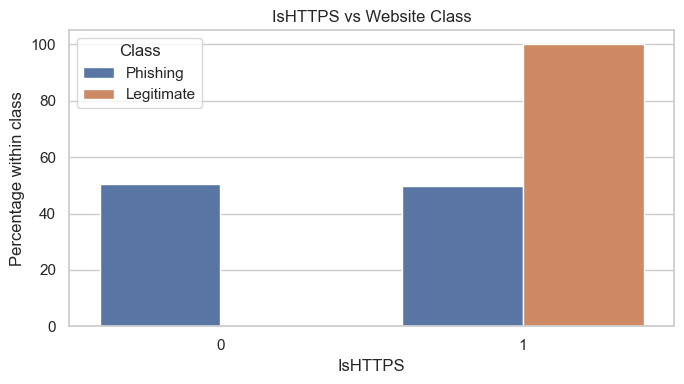

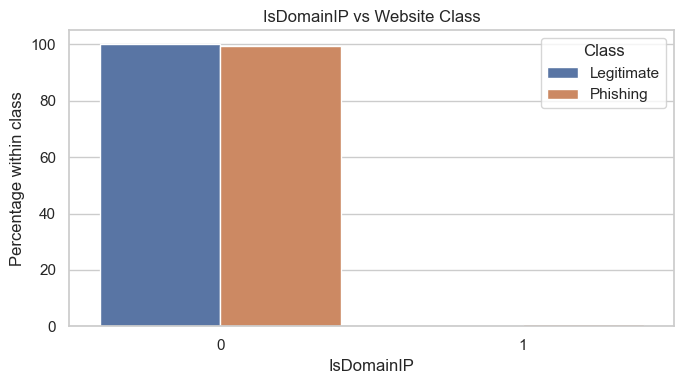

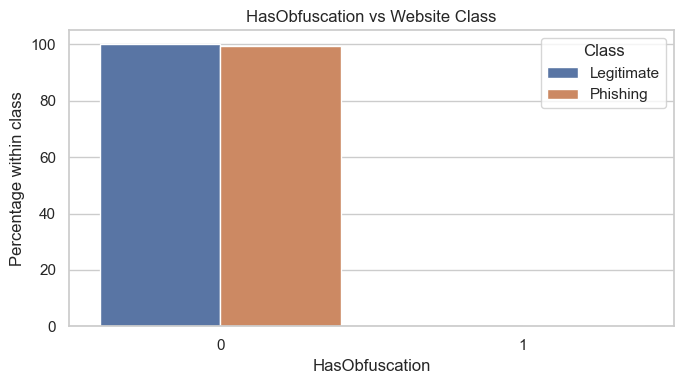

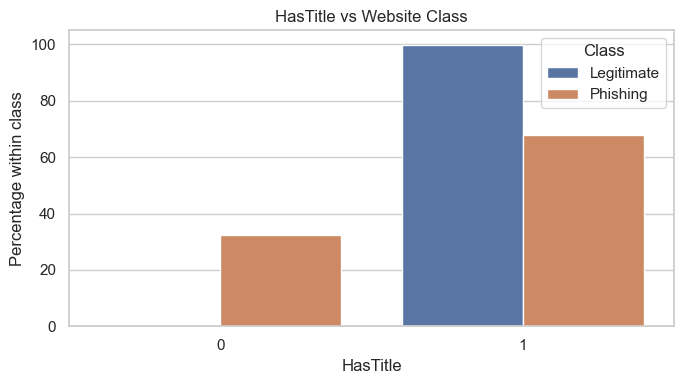

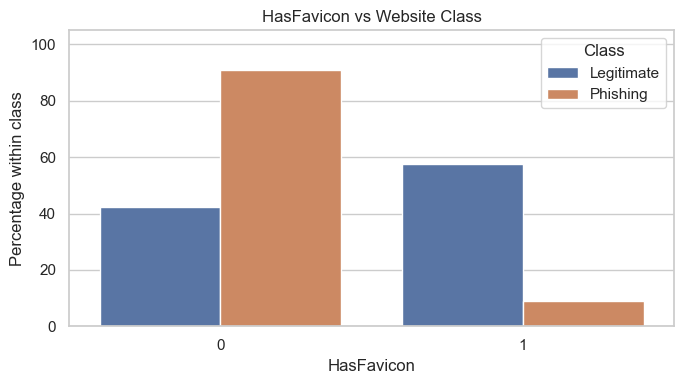

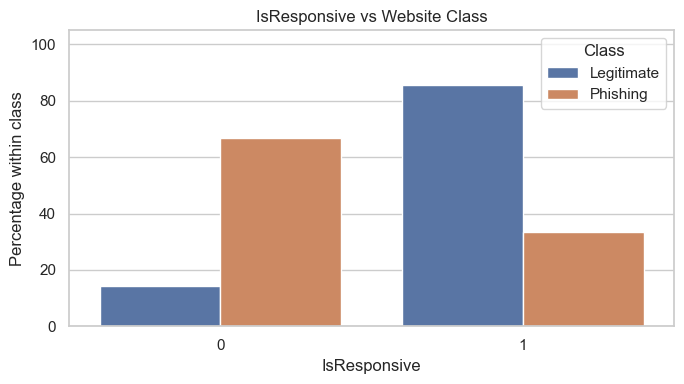

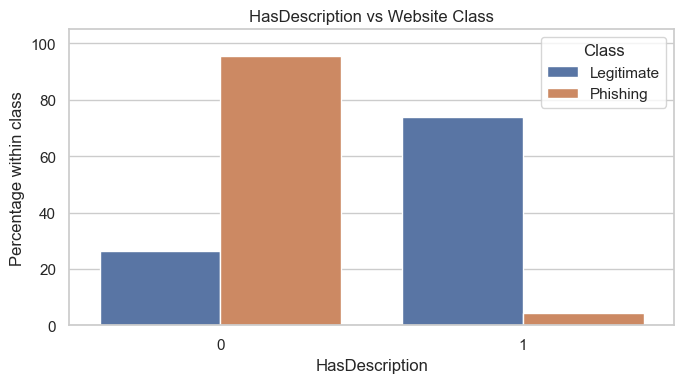

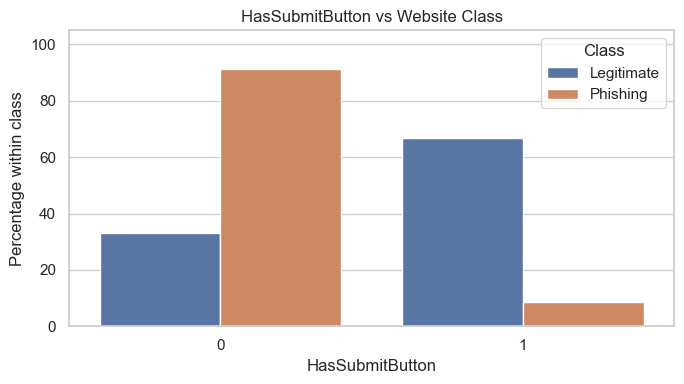

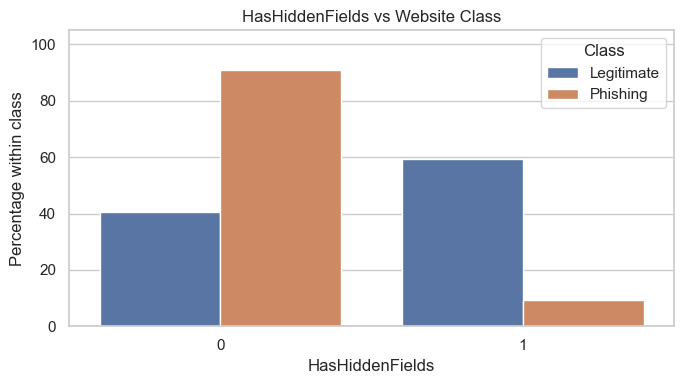

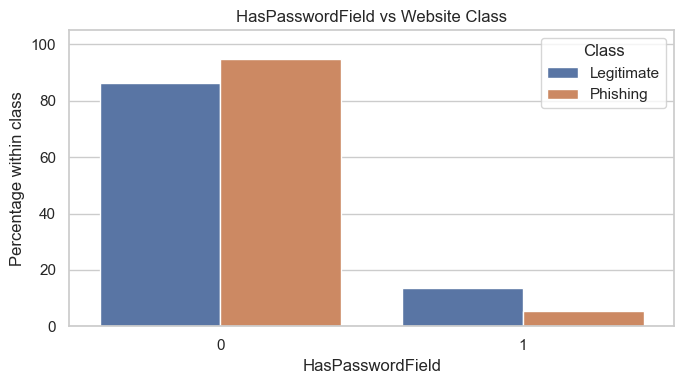

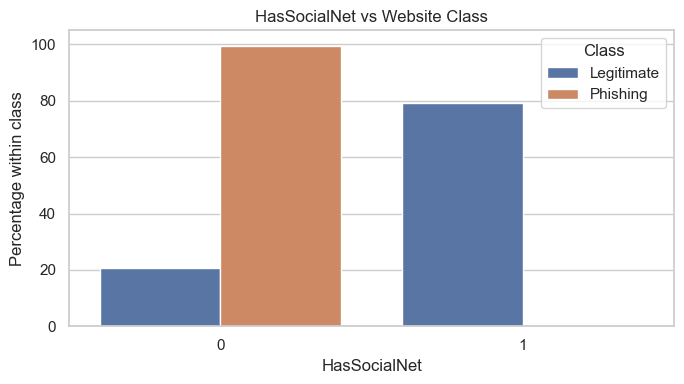

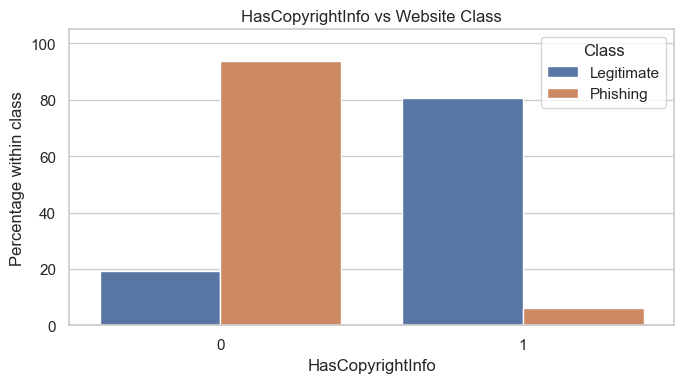

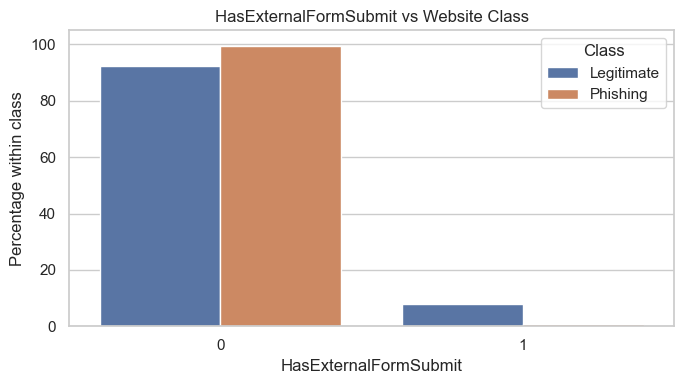

In [28]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

binary_features = [
    "IsHTTPS",
    "IsDomainIP",
    "HasObfuscation",
    "HasTitle",
    "HasFavicon",
    "IsResponsive",
    "HasDescription",
    "HasSubmitButton",
    "HasHiddenFields",
    "HasPasswordField",
    "HasSocialNet",
    "HasCopyrightInfo",
    "HasExternalFormSubmit"
]

for feature in binary_features:

    if feature not in plot_df.columns:
        continue

    # Percentage of each feature value within each class
    temp = (
        plot_df.groupby("Class")[feature]
        .value_counts(normalize=True)
        .mul(100)
        .rename("Percentage")
        .reset_index()
    )

    plt.figure(figsize=(7, 4))

    sns.barplot(
        data=temp,
        x=feature,
        y="Percentage",
        hue="Class"
    )

    plt.title(f"{feature} vs Website Class")
    plt.ylabel("Percentage within class")
    plt.xlabel(feature)
    plt.ylim(0, 105)

    plt.tight_layout()
    plt.show()


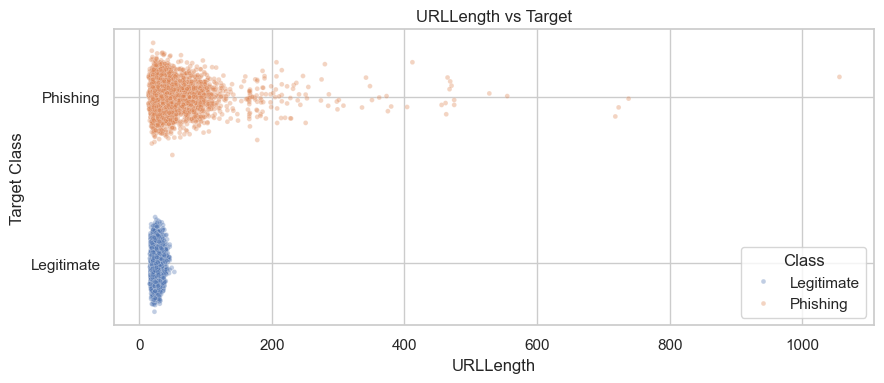

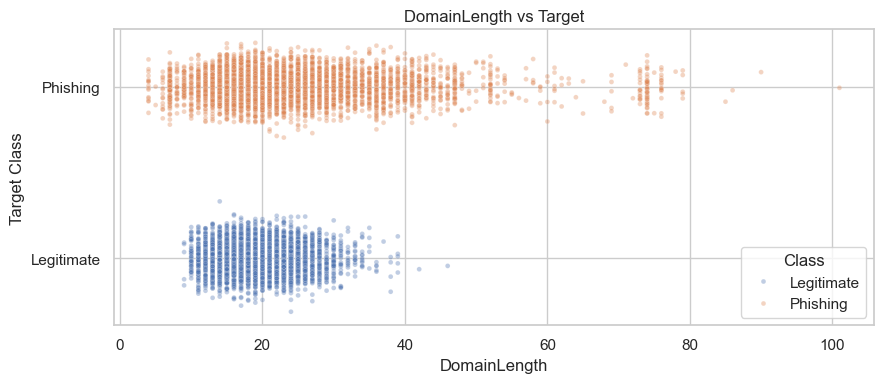

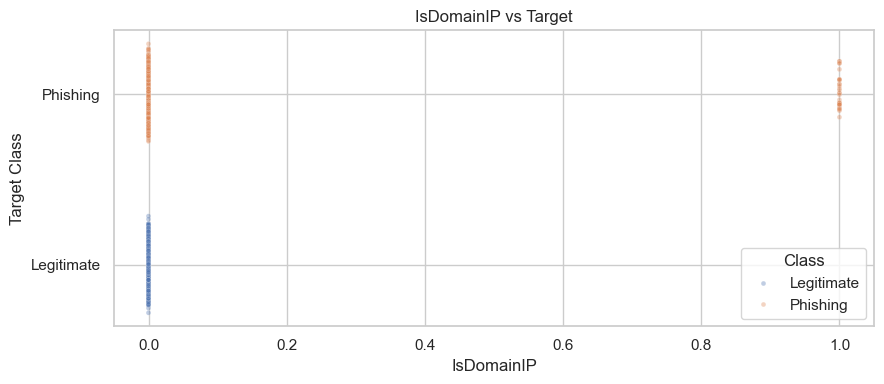

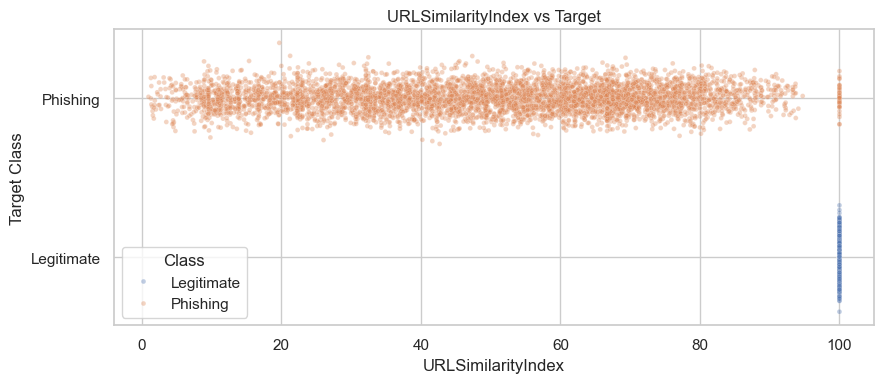

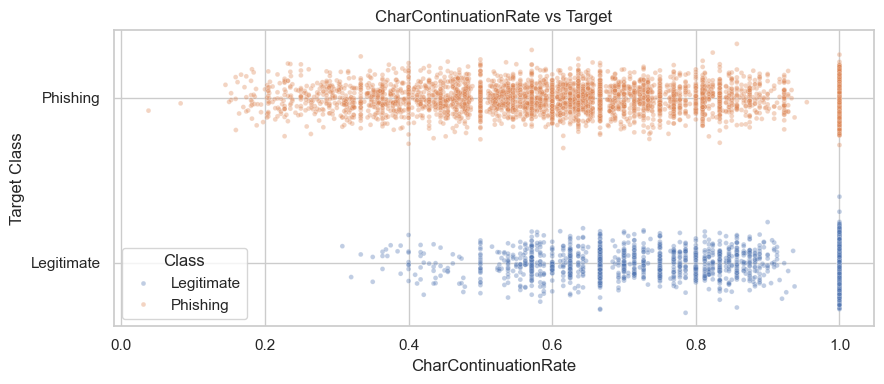

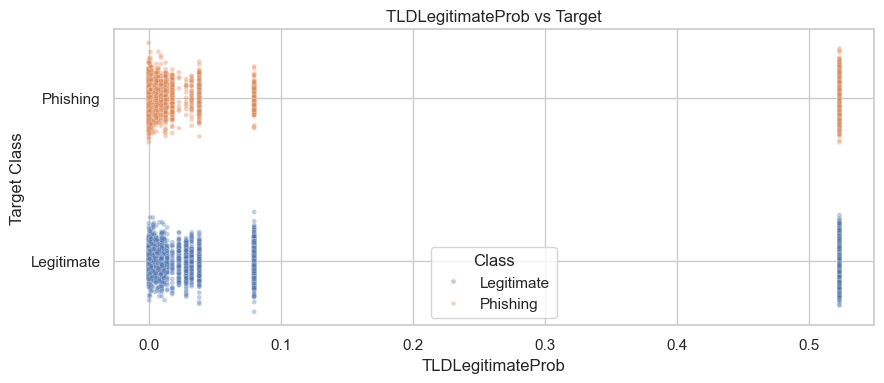

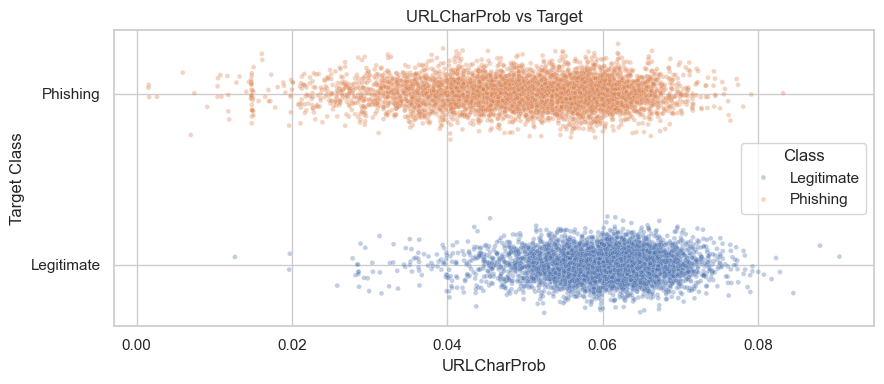

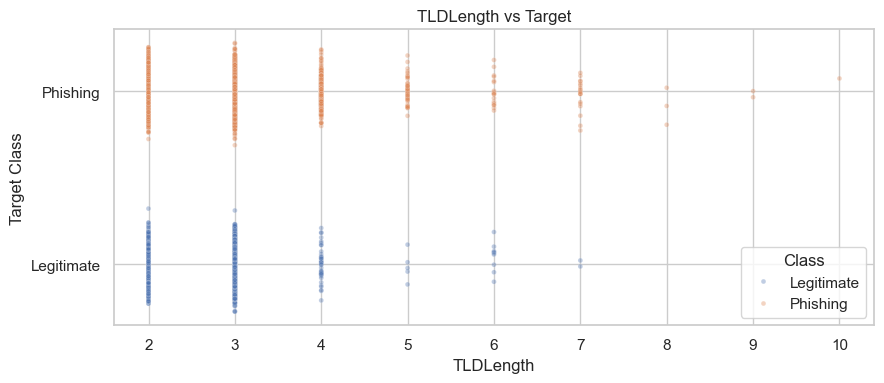

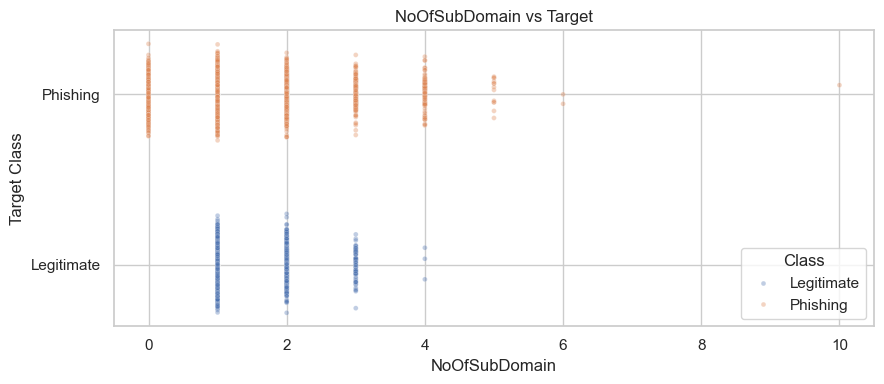

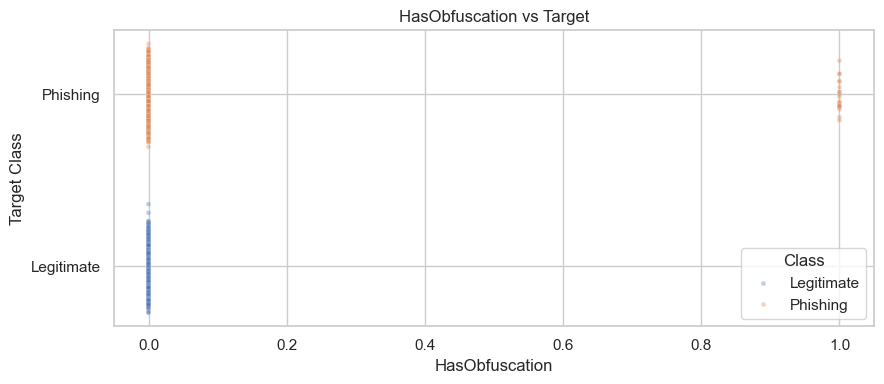

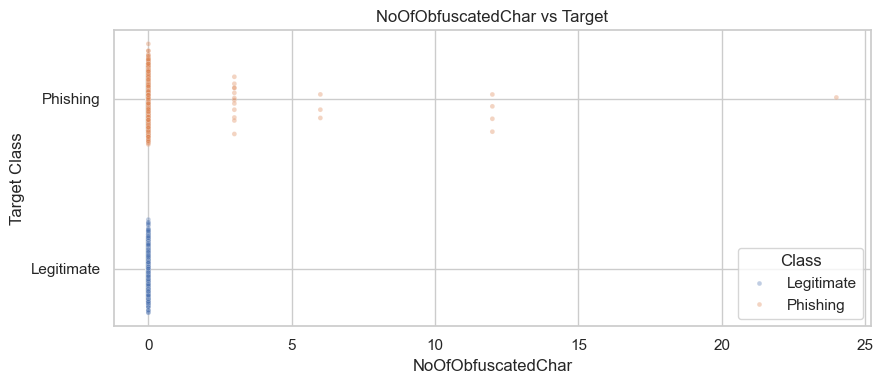

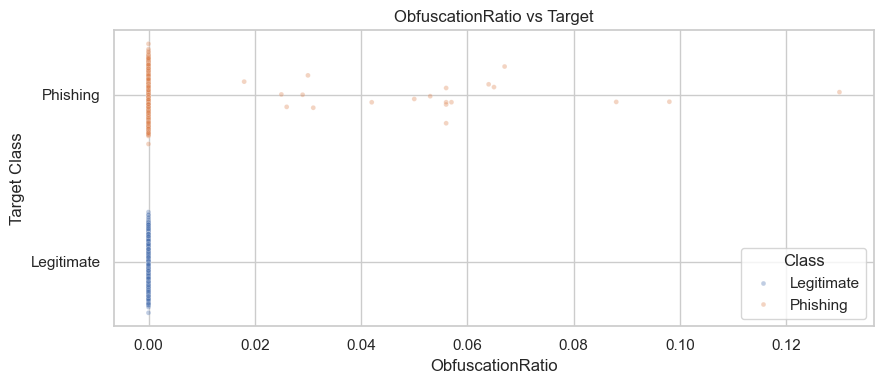

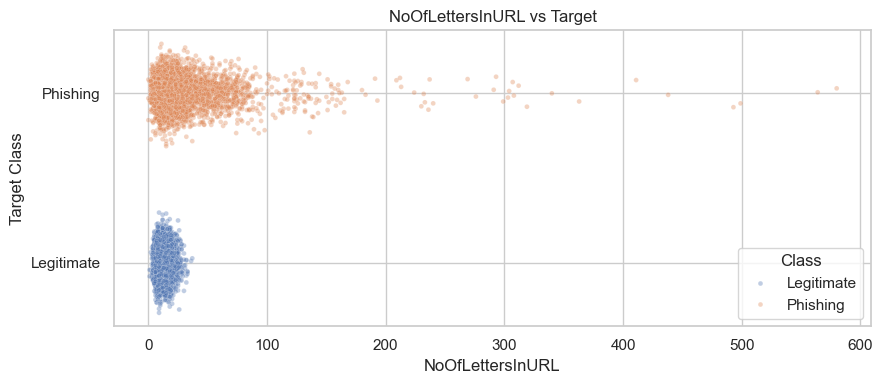

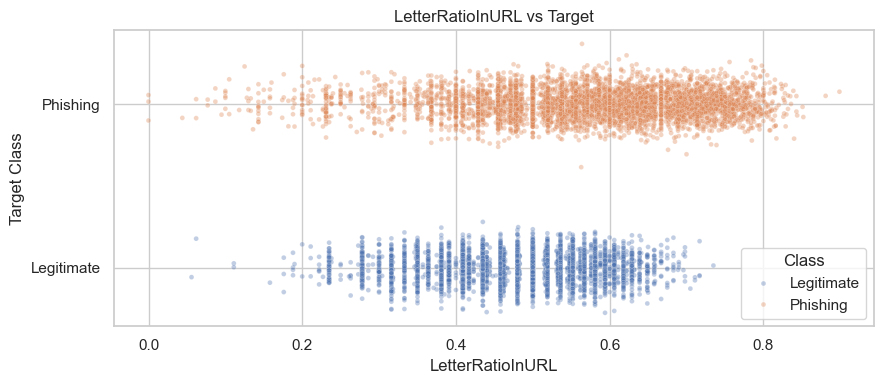

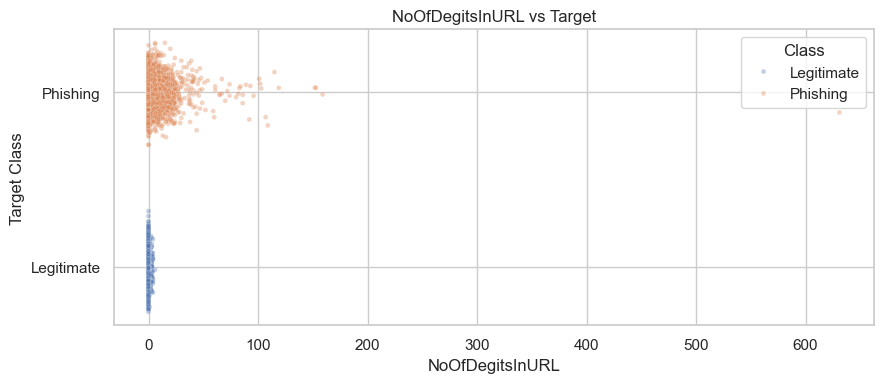

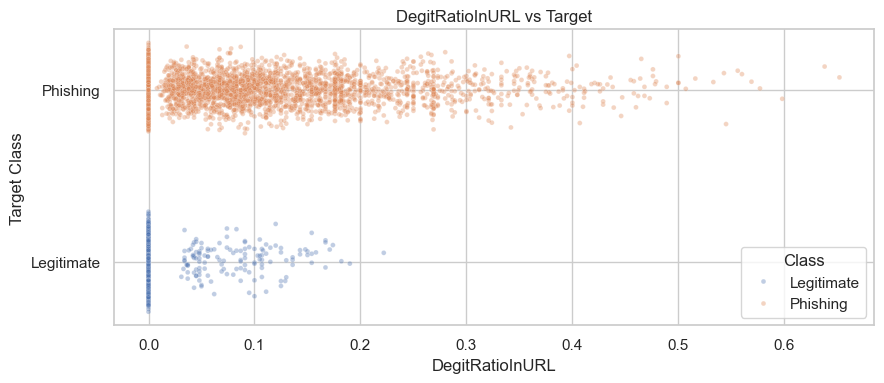

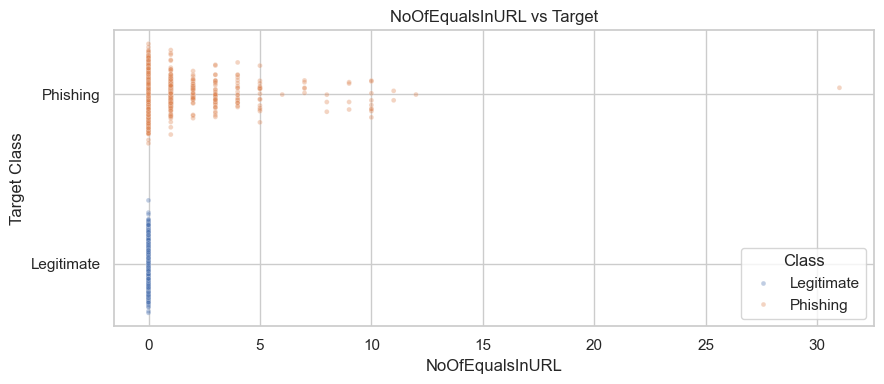

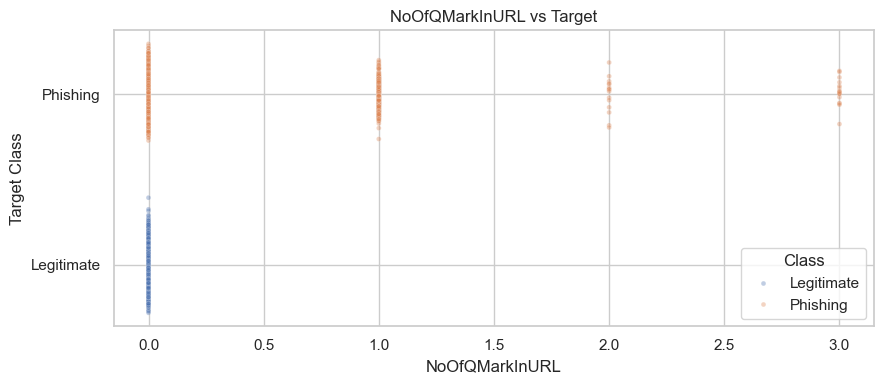

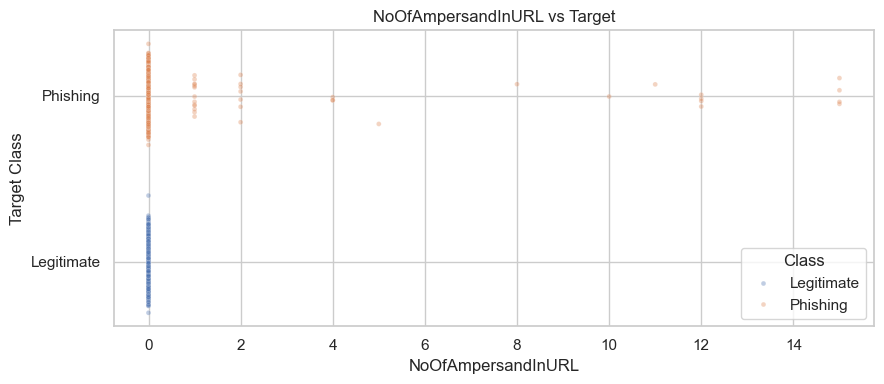

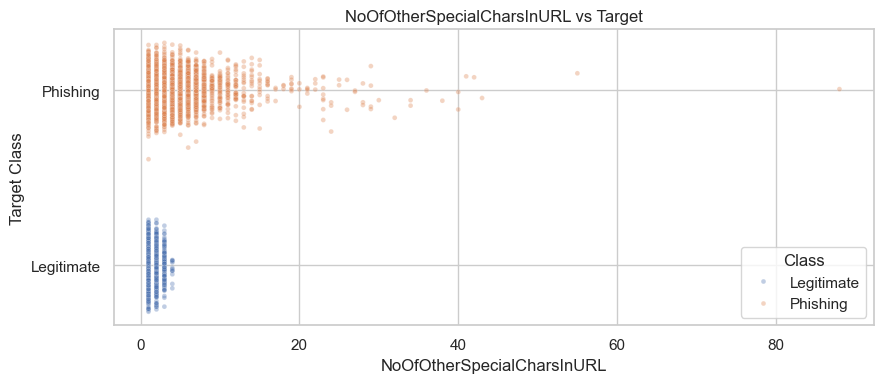

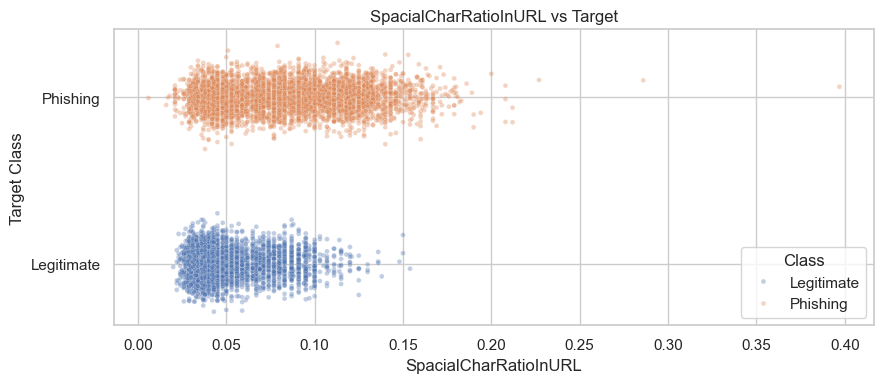

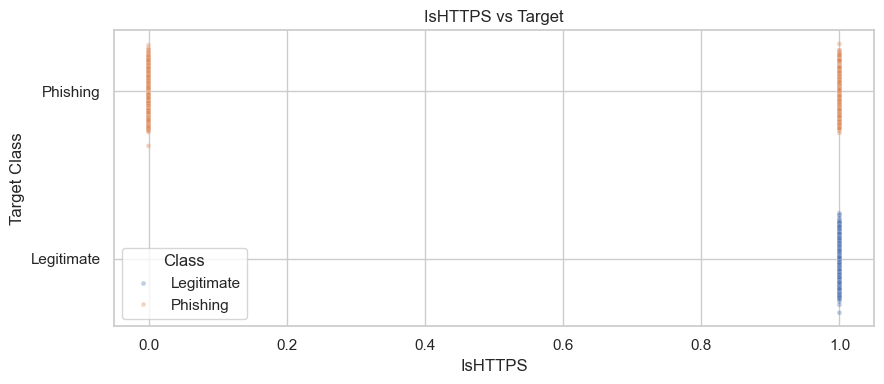

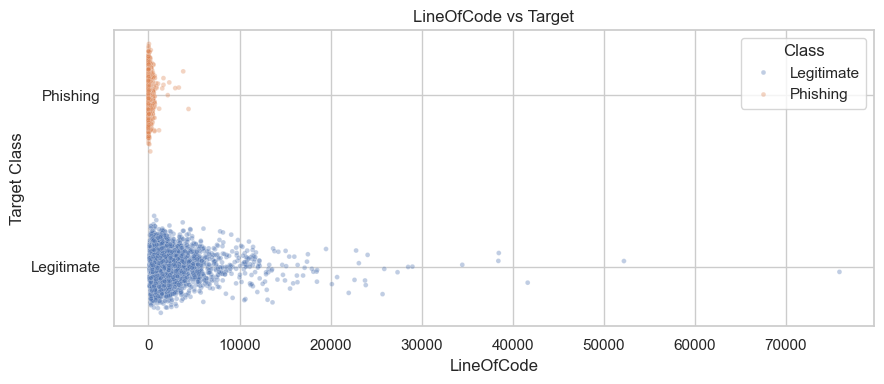

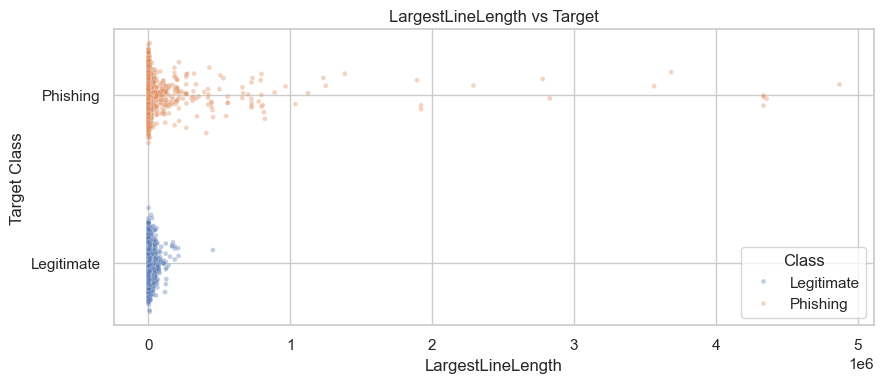

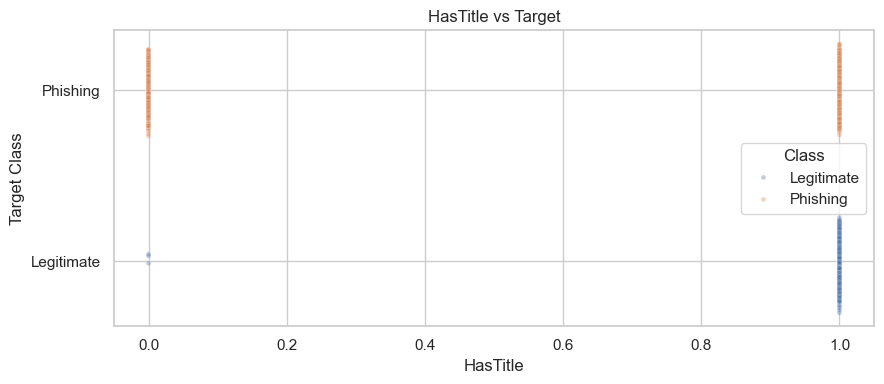

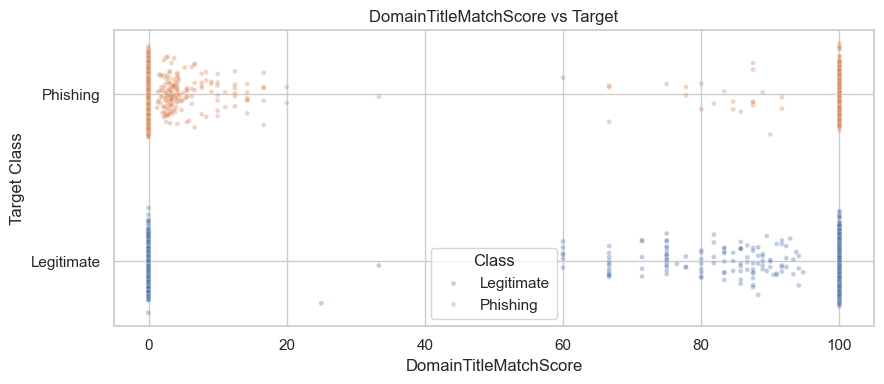

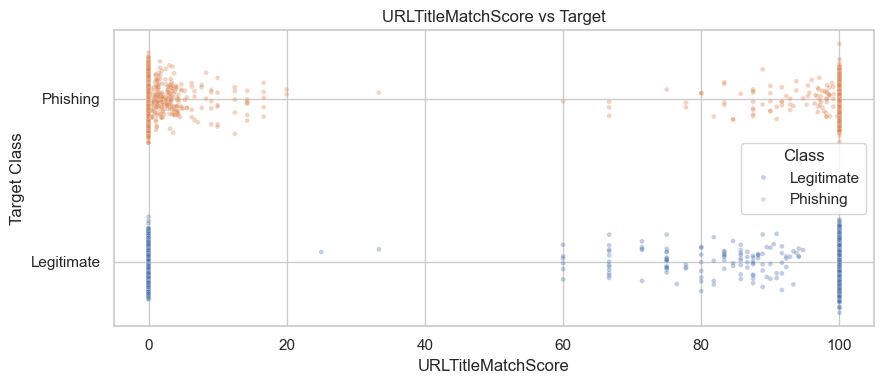

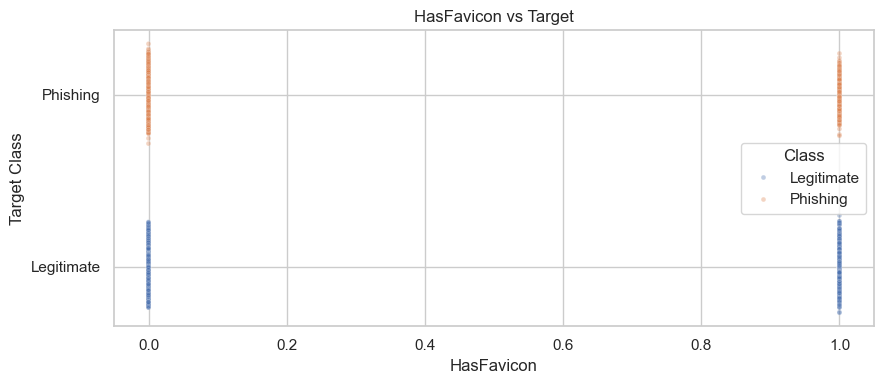

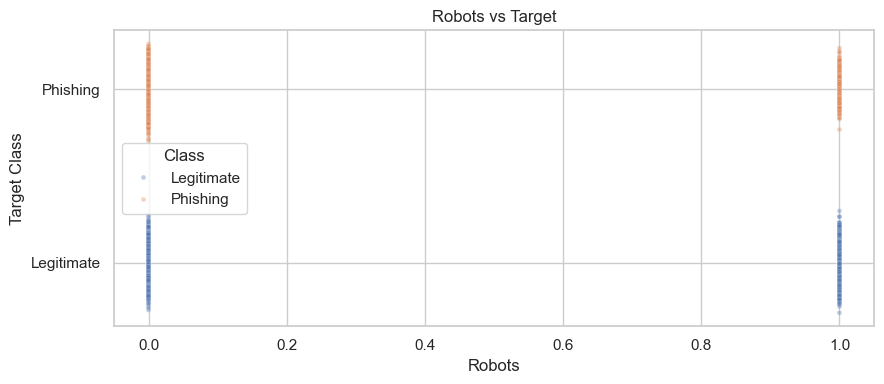

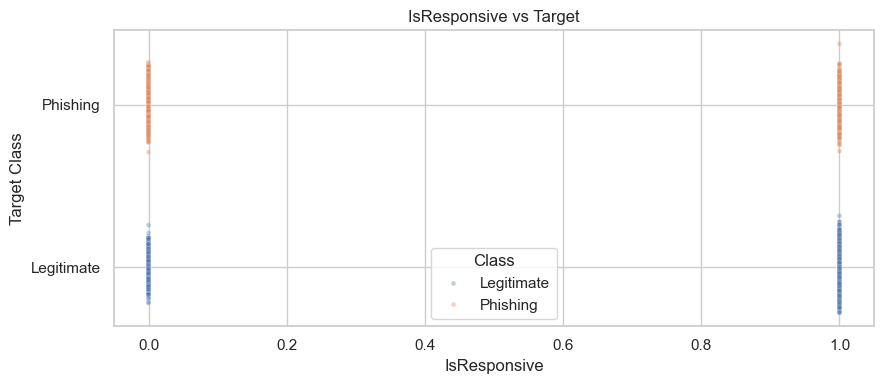

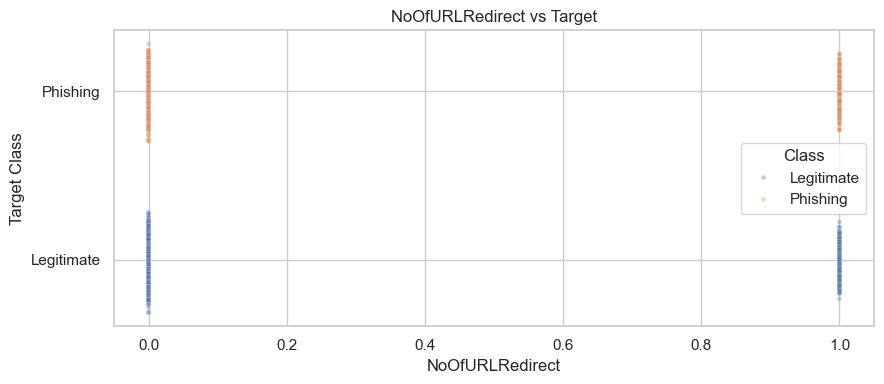

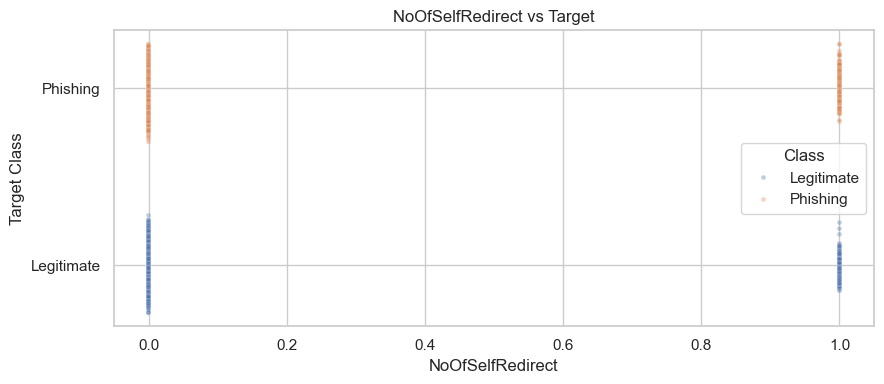

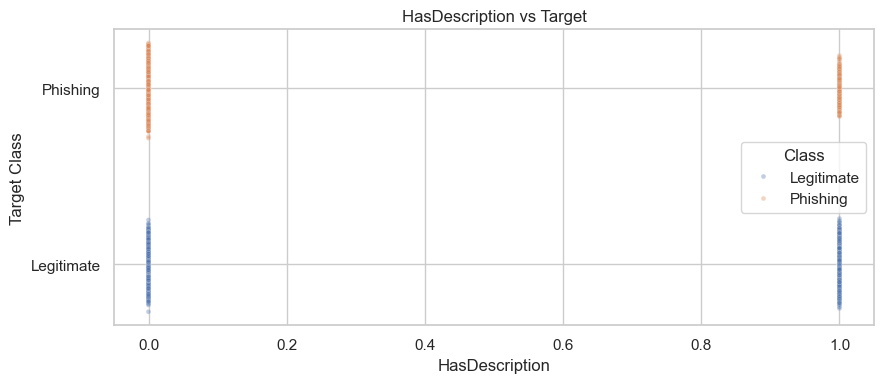

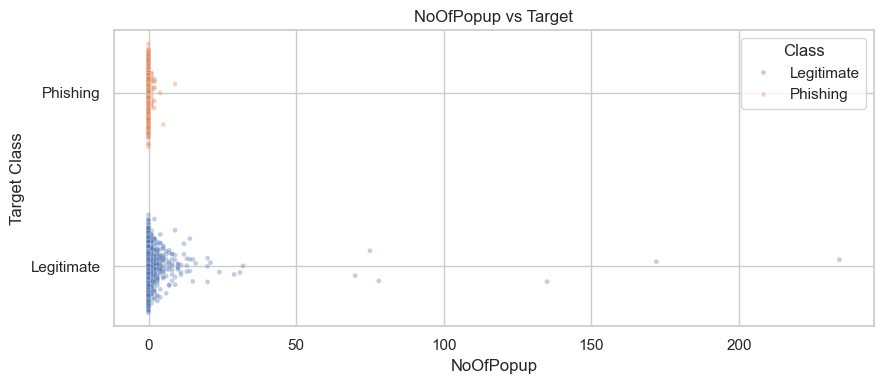

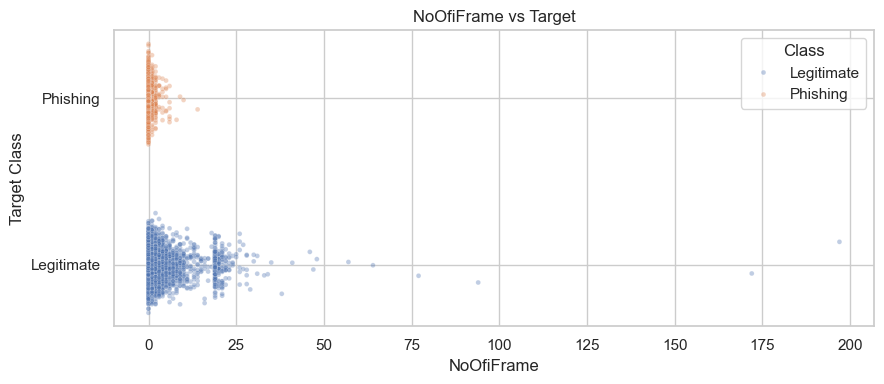

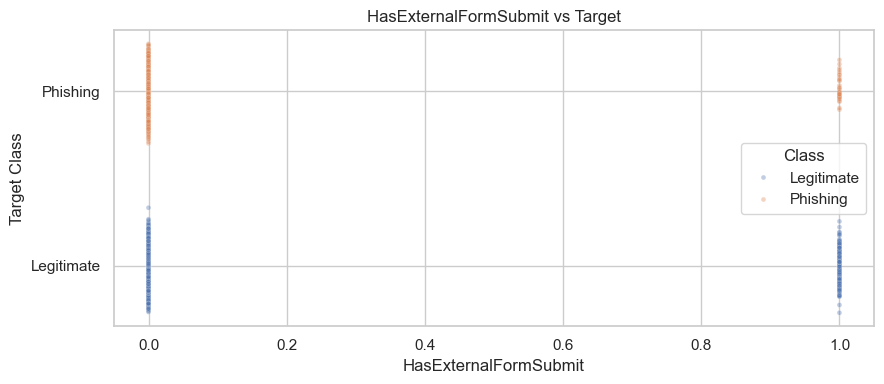

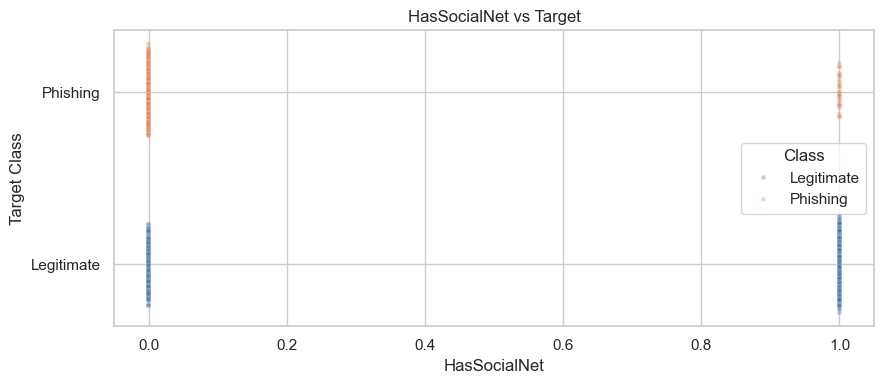

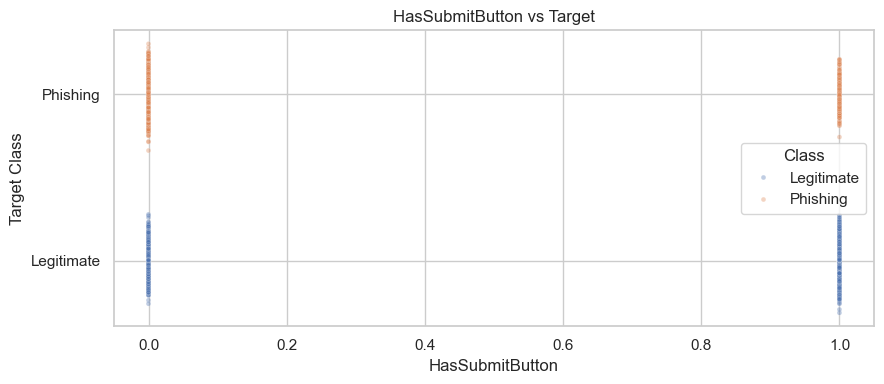

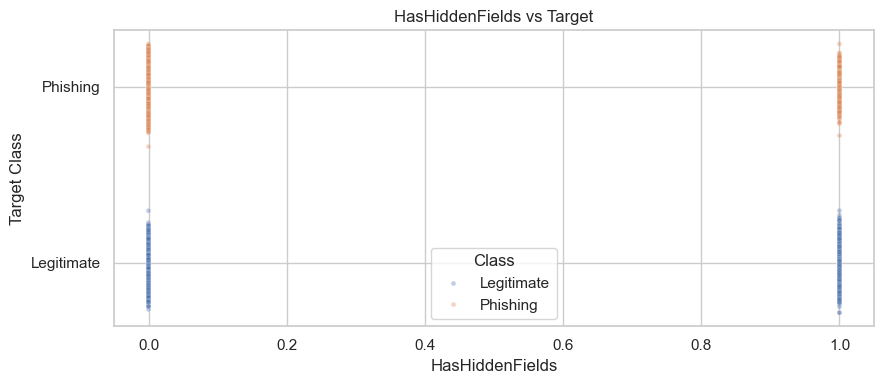

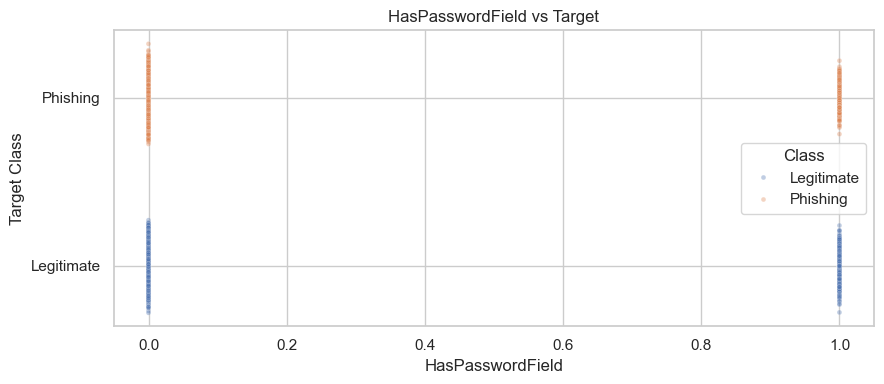

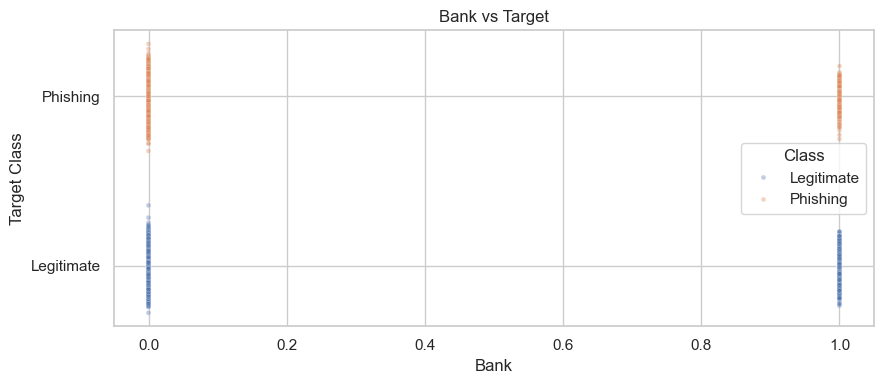

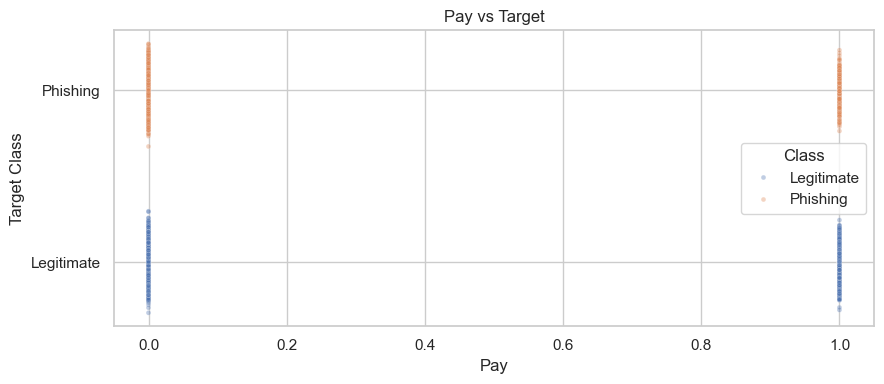

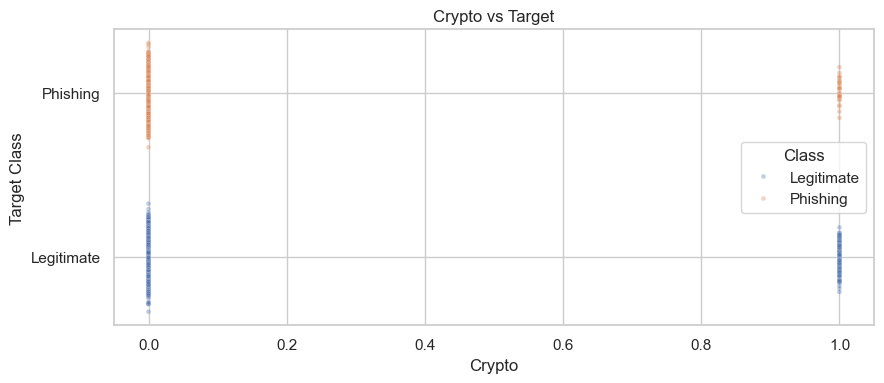

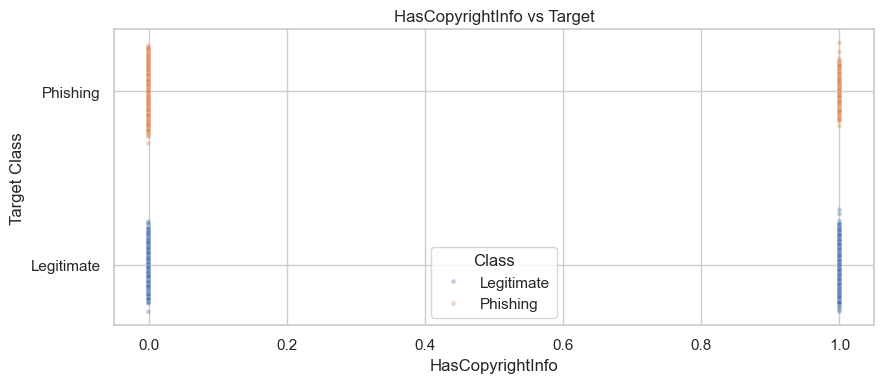

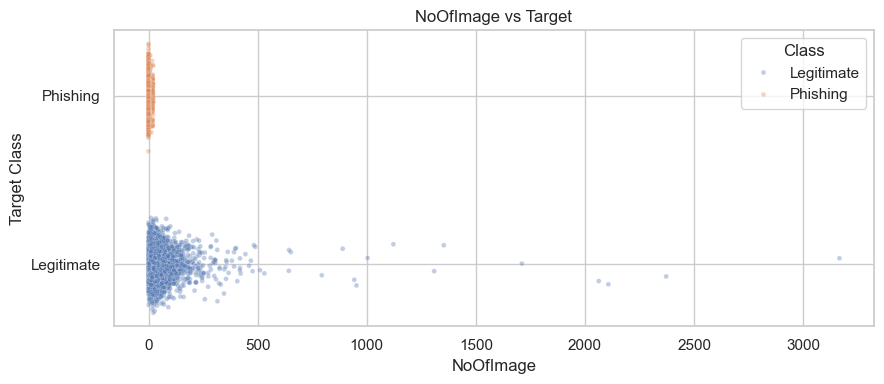

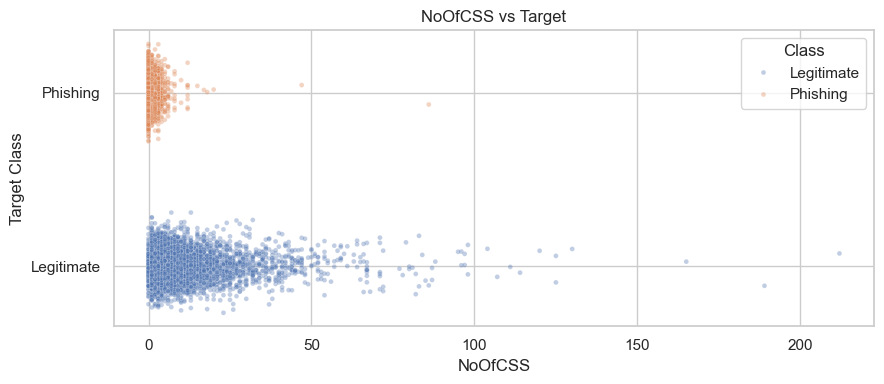

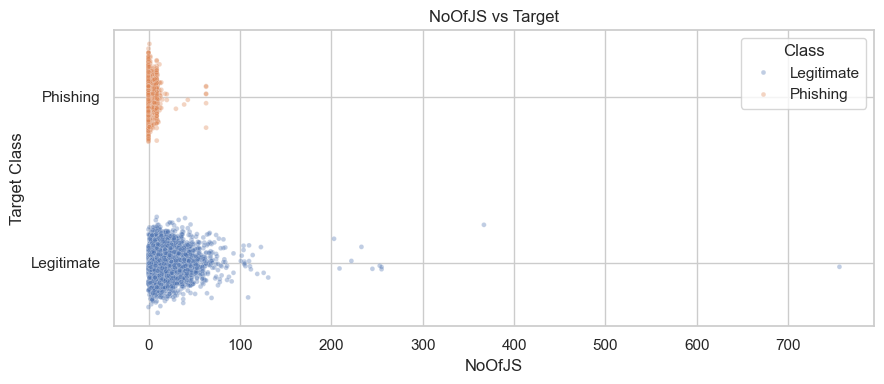

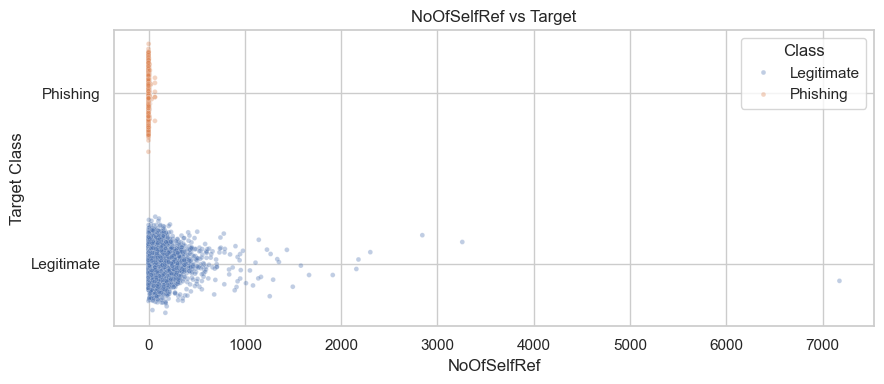

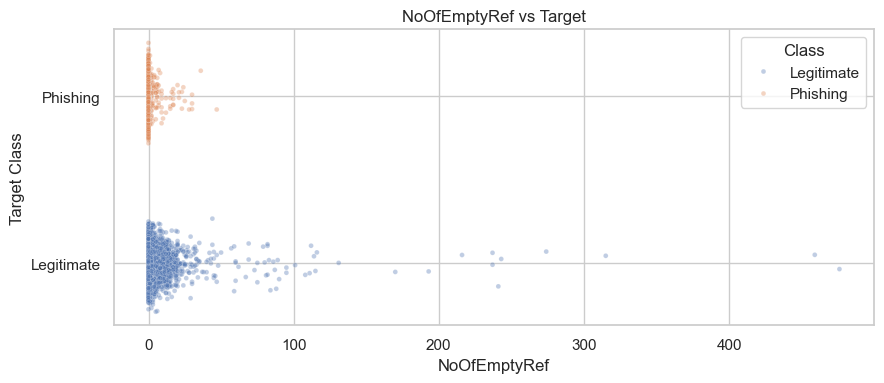

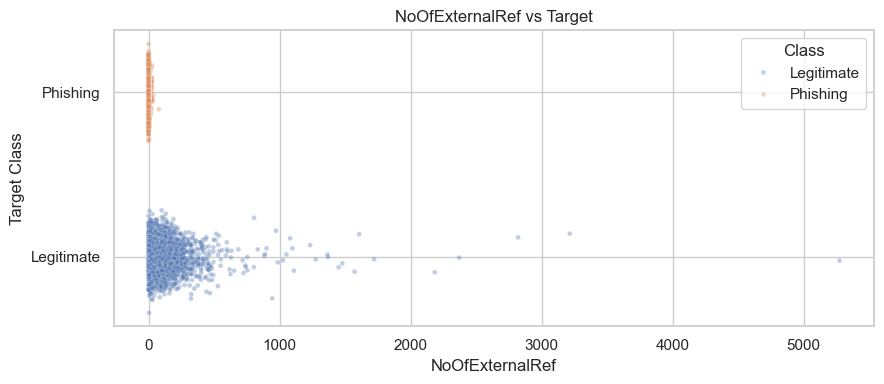

In [31]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use the numerical features from your dataset
numeric_features = X.select_dtypes(include="number").columns.tolist()

rng = np.random.default_rng(42)

for feature in numeric_features:

    plt.figure(figsize=(9, 4))

    # Add jitter so points don't overlap at target = 0 or 1
    temp = plot_df.copy()
    temp["Target_Jitter"] = (
        temp["target"]
        + rng.normal(0, 0.08, len(temp))
    )

    sns.scatterplot(
        data=temp,
        x=feature,
        y="Target_Jitter",
        hue="Class",
        hue_order=["Legitimate", "Phishing"],
        alpha=0.35,
        s=12
    )

    plt.yticks([0, 1], ["Legitimate", "Phishing"])
    plt.xlabel(feature)
    plt.ylabel("Target Class")
    plt.title(f"{feature} vs Target")

    plt.tight_layout()
    plt.show()


In [30]:

import pandas as pd

content_features = [
    "LineOfCode",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]

train_df = X_clean.iloc[train_idx].copy()
train_df["target"] = y.iloc[train_idx].to_numpy()

summary = []

for feature in content_features:
    for cls, name in [(0, "Legitimate"), (1, "Phishing")]:
        values = train_df.loc[
            train_df["target"] == cls, feature
        ]

        summary.append({
            "Feature": feature,
            "Class": name,
            "Mean": values.mean(),
            "Median": values.median(),
            "Zero %": (values == 0).mean() * 100,
            "Less than or equal to 5 %":
                (values <= 5).mean() * 100
        })

content_summary = pd.DataFrame(summary)
display(content_summary.round(2))


,Feature,Class,Mean,Median,Zero %,Less than or equal to 5 %
0,LineOfCode,Legitimate,1935.67,1105.0,0.00,0.00
1,LineOfCode,Phishing,67.07,11.0,0.00,31.27
2,NoOfImage,Legitimate,45.00,25.0,1.00,9.54
3,NoOfImage,Phishing,0.87,0.0,83.15,95.89
4,NoOfCSS,Legitimate,10.50,6.0,1.95,45.93
5,NoOfCSS,Phishing,0.45,0.0,80.30,99.12
6,NoOfJS,Legitimate,17.67,14.0,1.07,16.16
7,NoOfJS,Phishing,0.94,0.0,76.99,94.12
8,NoOfSelfRef,Legitimate,113.11,76.0,3.79,9.47
9,NoOfSelfRef,Phishing,0.54,0.0,78.63,99.12


In [32]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
import pandas as pd

experiments = {
    "Reduced Hybrid - 39 Features": X_clean.columns.tolist(),

    "Without HTML Content Counts": [
        col for col in X_clean.columns
        if col not in content_features
    ],

    "Content Counts Only": content_features
}

results = []

for name, cols in experiments.items():

    model = RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_clean.iloc[train_idx][cols],
        y.iloc[train_idx]
    )

    pred = model.predict(
        X_clean.iloc[val_idx][cols]
    )

    tn, fp, fn, tp = confusion_matrix(
        y.iloc[val_idx], pred
    ).ravel()

    results.append({
        "Experiment": name,
        "Features": len(cols),
        "Accuracy": accuracy_score(y.iloc[val_idx], pred),
        "Precision": precision_score(y.iloc[val_idx], pred),
        "Recall": recall_score(y.iloc[val_idx], pred),
        "F1": f1_score(y.iloc[val_idx], pred),
        "FP": fp,
        "FN": fn
    })

display(pd.DataFrame(results).round(4))


,Experiment,Features,Accuracy,Precision,Recall,F1,FP,FN
0,Reduced Hybrid - 39 Features,39,0.9992,0.9998,0.9982,0.9990,3,27
1,Without HTML Content Counts,32,0.9950,0.9957,0.9926,0.9942,65,111
2,Content Counts Only,7,0.9939,0.9956,0.9901,0.9928,66,150


,Records,Mean_Zero_Count,All_Seven_Zero,Five_Or_More_Zero
target,,,,
0,94426,0.5640,0.0,0.0000
1,71026,4.7071,0.0,0.6611


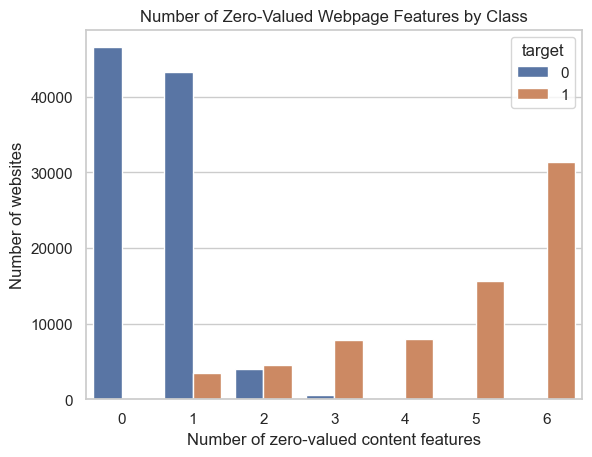

In [33]:

import pandas as pd
import numpy as np

content_features = [
    "LineOfCode",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]

train_content = X_clean.iloc[train_idx][content_features].copy()
train_content["target"] = y.iloc[train_idx].to_numpy()

# Number of zero-valued content features per record
train_content["ZeroCount"] = (
    train_content[content_features] == 0
).sum(axis=1)

# Check how many records have most content features equal to zero
summary = train_content.groupby("target").agg(
    Records=("ZeroCount", "size"),
    Mean_Zero_Count=("ZeroCount", "mean"),
    All_Seven_Zero=("ZeroCount", lambda s: (s == 7).mean()),
    Five_Or_More_Zero=("ZeroCount", lambda s: (s >= 5).mean())
)

display(summary.round(4))

# Distribution by class
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=train_content,
    x="ZeroCount",
    hue="target"
)

plt.title("Number of Zero-Valued Webpage Features by Class")
plt.xlabel("Number of zero-valued content features")
plt.ylabel("Number of websites")
plt.show()


In [34]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, f1_score
)

# 1 = webpage element present, 0 = absent
X_content_presence = (
    X_clean[content_features] > 0
).astype(int)

X_train_presence = X_content_presence.iloc[train_idx]
X_val_presence = X_content_presence.iloc[val_idx]

presence_model = RandomForestClassifier(
    n_estimators=150,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

presence_model.fit(
    X_train_presence,
    y.iloc[train_idx]
)

pred = presence_model.predict(X_val_presence)

print("Presence-only Accuracy:",
      accuracy_score(y.iloc[val_idx], pred))
print("Presence-only Recall:",
      recall_score(y.iloc[val_idx], pred))
print("Presence-only F1:",
      f1_score(y.iloc[val_idx], pred))


Presence-only Accuracy: 0.955144149236857
Presence-only Recall: 0.9380548562342653
Presence-only F1: 0.9469319511787326


In [35]:

import pandas as pd

from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Seven webpage-content features
content_features = [
    "LineOfCode",
    "NoOfImage",
    "NoOfCSS",
    "NoOfJS",
    "NoOfSelfRef",
    "NoOfEmptyRef",
    "NoOfExternalRef"
]

# Count how many of these features equal zero
zero_count = (
    X_clean[content_features] == 0
).sum(axis=1).to_frame("ZeroCount")

# Use your existing training-validation split
X_train_zero = zero_count.iloc[train_idx]
X_val_zero = zero_count.iloc[val_idx]

y_train_zero = y.iloc[train_idx]
y_val_zero = y.iloc[val_idx]

# Train a simple Decision Tree
zero_model = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=100,
    random_state=42
)

zero_model.fit(X_train_zero, y_train_zero)

# Predictions
y_pred = zero_model.predict(X_val_zero)

# Evaluation
print("ZERO-COUNT MODEL PERFORMANCE")
print("----------------------------")

print("Accuracy:", round(accuracy_score(y_val_zero, y_pred), 4))
print("Precision:", round(precision_score(y_val_zero, y_pred), 4))
print("Recall:", round(recall_score(y_val_zero, y_pred), 4))
print("F1 Score:", round(f1_score(y_val_zero, y_pred), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val_zero, y_pred))

# Display learned decision rules
print("\nDECISION TREE RULES")
print(export_text(
    zero_model,
    feature_names=["ZeroCount"]
))


ZERO-COUNT MODEL PERFORMANCE
----------------------------
Accuracy: 0.9523
Precision: 0.9372
Recall: 0.9518
F1 Score: 0.9445

Confusion Matrix:
[[19324   962]
 [  727 14367]]

DECISION TREE RULES
|--- ZeroCount <= 1.50
|   |--- ZeroCount <= 0.50
|   |   |--- class: 0
|   |--- ZeroCount >  0.50
|   |   |--- class: 0
|--- ZeroCount >  1.50
|   |--- ZeroCount <= 2.50
|   |   |--- class: 1
|   |--- ZeroCount >  2.50
|   |   |--- class: 1



In [36]:

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Validation features and labels
X_val = X_clean.iloc[val_idx]
y_val = y.iloc[val_idx]

# Count zero-valued webpage features
zero_count_val = (
    X_val[content_features] == 0
).sum(axis=1)

# Predict using the previously trained reduced hybrid model
predictions = rf_clean.predict(X_val)

group_results = []

for group_name, mask in {
    "Low sparsity (0-1 zeros)": zero_count_val <= 1,
    "High sparsity (2+ zeros)": zero_count_val >= 2
}.items():

    actual = y_val[mask]
    predicted = predictions[mask]

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    group_results.append({
        "Group": group_name,
        "Samples": len(actual),
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn
    })

display(pd.DataFrame(group_results).round(4))


,Group,Samples,Accuracy,Precision,Recall,F1,False Positives,False Negatives
0,Low sparsity (0-1 zeros),20051,0.9992,0.9958,0.9821,0.9889,3,13
1,High sparsity (2+ zeros),15329,0.9991,1.0000,0.9990,0.9995,0,14


In [37]:

import pandas as pd
import numpy as np

from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Use your original three feature groups
feature_groups = {
    "URL": X_url,
    "Webpage": X_webpage,
    "Hybrid": X_hybrid
}

# Number of features to test in each group
k_values = {
    "URL": [5, 8, 10, 12, 15, 18],
    "Webpage": [5, 10, 15, 20, 25, 28],
    "Hybrid": [5, 10, 15, 20, 30, 40, 46]
}

results = []
selected_features = {}

for group_name, X_group in feature_groups.items():

    X_train = X_group.iloc[train_idx]
    X_val = X_group.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    print(f"\n========== {group_name} ==========")

    for k in k_values[group_name]:

        # Feature selection + Random Forest pipeline
        pipeline = Pipeline([
            ("selector", SelectKBest(
                score_func=mutual_info_classif,
                k=k
            )),
            ("model", RandomForestClassifier(
                n_estimators=150,
                max_depth=20,
                random_state=42,
                n_jobs=-1
            ))
        ])

        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_val)

        tn, fp, fn, tp = confusion_matrix(
            y_val, y_pred, labels=[0, 1]
        ).ravel()

        # Store selected feature names
        mask = pipeline.named_steps[
            "selector"
        ].get_support()

        chosen = X_train.columns[mask].tolist()

        selected_features[(group_name, k)] = chosen

        results.append({
            "Feature Group": group_name,
            "K": k,
            "Accuracy": accuracy_score(y_val, y_pred),
            "Precision": precision_score(
                y_val, y_pred, zero_division=0
            ),
            "Recall": recall_score(
                y_val, y_pred, zero_division=0
            ),
            "F1": f1_score(
                y_val, y_pred, zero_division=0
            ),
            "FP": fp,
            "FN": fn
        })

        print(
            f"K={k:2d} | "
            f"Accuracy={accuracy_score(y_val, y_pred):.4f} | "
            f"Recall={recall_score(y_val, y_pred):.4f} | "
            f"F1={f1_score(y_val, y_pred):.4f}"
        )

# Final results table
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ["Feature Group", "K"]
    ).round(4)
)



========== URL ==========
K= 5 | Accuracy=0.9952 | Recall=0.9910 | F1=0.9943
K= 8 | Accuracy=0.9951 | Recall=0.9910 | F1=0.9943
K=10 | Accuracy=0.9972 | Recall=0.9947 | F1=0.9967
K=12 | Accuracy=0.9970 | Recall=0.9944 | F1=0.9965
K=15 | Accuracy=0.9970 | Recall=0.9944 | F1=0.9964
K=18 | Accuracy=0.9970 | Recall=0.9944 | F1=0.9965

========== Webpage ==========
K= 5 | Accuracy=0.9933 | Recall=0.9899 | F1=0.9922
K=10 | Accuracy=0.9961 | Recall=0.9940 | F1=0.9955
K=15 | Accuracy=0.9976 | Recall=0.9963 | F1=0.9972
K=20 | Accuracy=0.9975 | Recall=0.9958 | F1=0.9970
K=25 | Accuracy=0.9974 | Recall=0.9955 | F1=0.9969
K=28 | Accuracy=0.9975 | Recall=0.9957 | F1=0.9971

========== Hybrid ==========
K= 5 | Accuracy=0.9933 | Recall=0.9899 | F1=0.9922


KeyboardInterrupt: 

In [38]:

# Features to remove before feature selection
remove_features = [
    # HTTPS
    "IsHTTPS",

    # Suspicious engineered features
    "URLSimilarityIndex",
    "TLDLegitimateProb",
    "URLCharProb",
    "CharContinuationRate",

    # Redundant ratio features
    "LetterRatioInURL",
    "DegitRatioInURL",
    "ObfuscationRatio",
    "SpacialCharRatioInURL",

    # Highly correlated features
    "NoOfLettersInURL",
    "URLTitleMatchScore"
]

# Create cleaned feature groups
clean_url_features = [
    col for col in url_features
    if col not in remove_features
]

clean_webpage_features = [
    col for col in webpage_features
    if col not in remove_features
]

clean_hybrid_features = (
    clean_url_features + clean_webpage_features
)

# Create cleaned datasets
X_url_clean = X[clean_url_features].copy()
X_webpage_clean = X[clean_webpage_features].copy()
X_hybrid_clean = X[clean_hybrid_features].copy()

print("Clean URL features:", X_url_clean.shape[1])
print("Clean Webpage features:", X_webpage_clean.shape[1])
print("Clean Hybrid features:", X_hybrid_clean.shape[1])

print("\nRemoved features:")
print(remove_features)


Clean URL features: 12
Clean Webpage features: 27
Clean Hybrid features: 39

Removed features:
['IsHTTPS', 'URLSimilarityIndex', 'TLDLegitimateProb', 'URLCharProb', 'CharContinuationRate', 'LetterRatioInURL', 'DegitRatioInURL', 'ObfuscationRatio', 'SpacialCharRatioInURL', 'NoOfLettersInURL', 'URLTitleMatchScore']


In [39]:

import pandas as pd
import numpy as np

from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Cleaned feature groups
feature_groups = {
    "URL": X_url_clean,
    "Webpage": X_webpage_clean,
    "Hybrid": X_hybrid_clean
}

# Number of selected features to test
k_values = {
    "URL": [3, 5, 8, 10, 12],
    "Webpage": [5, 10, 15, 20, 25, 27],
    "Hybrid": [5, 10, 15, 20, 25, 30, 35, 39]
}

results = []
selected_features = {}
mi_rankings = {}

for group_name, X_group in feature_groups.items():

    X_train = X_group.iloc[train_idx]
    X_val = X_group.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    print(f"\n========== {group_name} ==========")

    # Mutual Information is calculated on training data only
    mi_scores = mutual_info_classif(
        X_train,
        y_train,
        random_state=42
    )

    # Rank features from highest to lowest MI
    ranking = pd.Series(
        mi_scores,
        index=X_train.columns
    ).sort_values(ascending=False)

    mi_rankings[group_name] = ranking

    for k in k_values[group_name]:

        # Select top K features
        features = ranking.head(k).index.tolist()

        # Train a new Random Forest
        model = RandomForestClassifier(
            n_estimators=150,
            max_depth=20,
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_train[features], y_train)

        # Validation predictions
        pred = model.predict(X_val[features])

        tn, fp, fn, tp = confusion_matrix(
            y_val, pred, labels=[0, 1]
        ).ravel()

        results.append({
            "Group": group_name,
            "K": k,
            "Accuracy": accuracy_score(y_val, pred),
            "Precision": precision_score(y_val, pred),
            "Recall": recall_score(y_val, pred),
            "F1": f1_score(y_val, pred),
            "FP": fp,
            "FN": fn
        })

        selected_features[(group_name, k)] = features

        print(
            f"K={k:2d} | "
            f"Accuracy={accuracy_score(y_val, pred):.4f} | "
            f"Recall={recall_score(y_val, pred):.4f} | "
            f"F1={f1_score(y_val, pred):.4f}"
        )

# Final comparison table
results_df = pd.DataFrame(results)

display(results_df.round(4))



========== URL ==========
K= 3 | Accuracy=0.8280 | Recall=0.6515 | F1=0.7637
K= 5 | Accuracy=0.9624 | Recall=0.9189 | F1=0.9542
K= 8 | Accuracy=0.9623 | Recall=0.9210 | F1=0.9542
K=10 | Accuracy=0.9623 | Recall=0.9205 | F1=0.9542
K=12 | Accuracy=0.9621 | Recall=0.9208 | F1=0.9540

========== Webpage ==========
K= 5 | Accuracy=0.9933 | Recall=0.9900 | F1=0.9921
K=10 | Accuracy=0.9962 | Recall=0.9940 | F1=0.9955
K=15 | Accuracy=0.9972 | Recall=0.9950 | F1=0.9967
K=20 | Accuracy=0.9972 | Recall=0.9952 | F1=0.9967
K=25 | Accuracy=0.9975 | Recall=0.9955 | F1=0.9971
K=27 | Accuracy=0.9973 | Recall=0.9951 | F1=0.9968

========== Hybrid ==========
K= 5 | Accuracy=0.9933 | Recall=0.9900 | F1=0.9921
K=10 | Accuracy=0.9962 | Recall=0.9940 | F1=0.9955
K=15 | Accuracy=0.9988 | Recall=0.9978 | F1=0.9986
K=20 | Accuracy=0.9986 | Recall=0.9972 | F1=0.9983
K=25 | Accuracy=0.9992 | Recall=0.9985 | F1=0.9991
K=30 | Accuracy=0.9992 | Recall=0.9983 | F1=0.9990
K=35 | Accuracy=0.9992 | Recall=0.9983 | F1=0

,Group,K,Accuracy,Precision,Recall,F1,FP,FN
0,URL,3,0.8280,0.9228,0.6515,0.7637,823,5261
1,URL,5,0.9624,0.9923,0.9189,0.9542,108,1224
2,URL,8,0.9623,0.9899,0.9210,0.9542,142,1193
3,URL,10,0.9623,0.9904,0.9205,0.9542,134,1200
4,URL,12,0.9621,0.9897,0.9208,0.9540,145,1196
5,Webpage,5,0.9933,0.9942,0.9900,0.9921,87,151
6,Webpage,10,0.9962,0.9971,0.9940,0.9955,44,91
7,Webpage,15,0.9972,0.9983,0.9950,0.9967,25,75
8,Webpage,20,0.9972,0.9983,0.9952,0.9967,26,72
9,Webpage,25,0.9975,0.9987,0.9955,0.9971,19,68
